# THÀNH VIÊN 3: MÔ HÌNH HOÁ TƯƠNG QUAN ĐỘNG (DCC-GARCH ESTIMATION)

**Vị trí trong chuỗi:** TV2 `std_resid.csv` (ε), `cond_vol.csv` (σ) → **TV3** → `dcc_matrices.npz` ($R_t$, $H_t$) → TV4 (VaR) & TV5 (Euler)

| Bước | Nội dung | File output |
|---|---|---|
| 1 | Ước lượng DCC(1,1) bằng QMLE bước 2: tham số a, b; kiểm tra a ≥ 0, b ≥ 0, a + b < 1 | `dcc_params.csv` |
| 1c–d | Tính $R_t$ và $H_t = D_t R_t D_t$ cho mọi ngày + dự báo $H_{T+1}$ | **`dcc_matrices.npz`**, `dynamic_correlations.csv` |
| 2 | So sánh DCC vs CCC vs hiệp phương sai tĩnh (LL, AIC, BIC, LR test) | `model_benchmark.csv` |
| 3 | Vẽ tương quan động các cặp (VCB–VHM, HPG–FPT), giai đoạn bình thường vs khủng hoảng | `dcc_pairs.png`, `corr_by_period.csv` |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats

from project_config import *

OUT_DIR = TV3_DIR
log_ret = read_panel(require(FILES["log_returns"], "TV1_Data_EDA"))
eps_df = read_panel(require(FILES["std_resid"], "TV2_GARCH"))
sig_df = read_panel(require(FILES["cond_vol"], "TV2_GARCH"))
garch_sel = pd.read_csv(require(FILES["garch_selected"], "TV2_GARCH"), index_col=0)
sigma_fcst = pd.read_csv(require(FILES["sigma_fcst"], "TV2_GARCH"), index_col=0).iloc[:, 0]

# Kiểm tra tính tương thích giữa output TV1 và TV2
tickers = list(eps_df.columns)
assert list(sig_df.columns) == tickers and list(log_ret.columns) == tickers, "Thứ tự mã giữa TV1/TV2 không khớp"
assert eps_df.index.equals(sig_df.index) and eps_df.index.equals(log_ret.index), "Ngày giữa TV1/TV2 không khớp"

dates = eps_df.index
eps = eps_df.values                       # T x N phần dư chuẩn hoá
sig = sig_df.values                       # T x N độ lệch chuẩn có điều kiện
mu = garch_sel.loc[tickers, "mu"].values  # N trung bình có điều kiện (hằng số)
u = log_ret.values - mu                   # T x N cú sốc ε_t chưa chuẩn hoá = r_t − μ
T, N = eps.shape
print(f"Đầu vào DCC: {T} phiên x {N} mã ({', '.join(tickers)})")
print("Mô hình biên từ TV2:", dict(garch_sel["Model"]))

Đầu vào DCC: 1452 phiên x 5 mã (FPT, HPG, MWG, VCB, VHM)
Mô hình biên từ TV2: {'FPT': 'GJR-GARCH-t', 'HPG': 'GJR-GARCH-t', 'MWG': 'GJR-GARCH-t', 'VCB': 'GARCH-t', 'VHM': 'GARCH-t'}


## 1. Ước lượng DCC-GARCH (Engle, 2002)

**Tầng 1 – Công thức & ý nghĩa**

a. Cập nhật $Q_t$: $\;Q_t = (1-a-b)\bar Q + a\,\epsilon_{t-1}\epsilon_{t-1}' + b\,Q_{t-1}$, với $\bar Q = \frac1T\sum_t \epsilon_t\epsilon_t'$ (correlation targeting)

b. Điều kiện dừng: $a \ge 0,\; b \ge 0,\; a+b<1$ ⇒ $Q_t$ xác định dương và quay về $\bar Q$ trong dài hạn.

c. $R_t = \operatorname{diag}(Q_t)^{-1/2}\,Q_t\,\operatorname{diag}(Q_t)^{-1/2}$ (chuẩn hoá để đường chéo = 1)

d. $H_t = D_t R_t D_t$, $D_t = \operatorname{diag}(\sigma_{1,t},\dots,\sigma_{N,t})$

Log-likelihood **phần tương quan** (bước 2 của ước lượng hai bước):
$$\ell_C(a,b) = -\tfrac12\sum_t\left[\ln|R_t| + \epsilon_t' R_t^{-1}\epsilon_t - \epsilon_t'\epsilon_t\right]$$

- **a** – phản ứng của tương quan với cú sốc chung mới (tin tức hôm qua) · **b** – độ bền của tương quan · **a + b** gần 1 ⇒ tương quan lệch khỏi mức trung bình rất lâu mới quay lại.

**Tầng 2:** `dcc_filter(a, b, eps)` → mảng `Q` (T×N×N), `R` (T×N×N). `dcc_negloglik` → −ℓ_C. Tối ưu bằng SLSQP với ràng buộc a + b < 1. Sai số chuẩn từ Hessian số.

**Tầng 3:** a thường nhỏ (0,01–0,05), b lớn (0,9–0,99). a có ý nghĩa thống kê ⇒ tương quan thực sự thay đổi theo thời gian (bác bỏ CCC).

In [2]:
# ===================== 1a–c. BỘ LỌC DCC =====================
Qbar = eps.T @ eps / T


def dcc_filter(a, b, eps, Qbar):
    """Trả về Q_t, R_t cho t = 0..T-1 và Q_{T}, R_{T} (dự báo 1 bước)."""
    T, N = eps.shape
    Q = np.empty((T + 1, N, N))
    Q[0] = Qbar                                   # Q_0 = Q̄
    const = (1 - a - b) * Qbar
    for t in range(1, T + 1):
        e = eps[t - 1][:, None]
        Q[t] = const + a * (e @ e.T) + b * Q[t - 1]
    d = 1 / np.sqrt(np.einsum("tii->ti", Q))
    R = Q * d[:, :, None] * d[:, None, :]
    return Q[:T], R[:T], Q[T], R[T]


def corr_loglik_terms(R, eps):
    """ℓ_C,t = −½[ln|R_t| + ε'R⁻¹ε − ε'ε]."""
    sign, logdet = np.linalg.slogdet(R)
    quad = np.einsum("ti,ti->t", eps, np.linalg.solve(R, eps[:, :, None])[:, :, 0])
    return -0.5 * (logdet + quad - np.einsum("ti,ti->t", eps, eps))


def dcc_negloglik(theta, eps, Qbar):
    a, b = theta
    if a < 0 or b < 0 or a + b >= 1:
        return 1e10
    _, R, _, _ = dcc_filter(a, b, eps, Qbar)
    return -np.sum(corr_loglik_terms(R, eps))


best = None
for x0 in [(0.02, 0.95), (0.05, 0.90), (0.01, 0.98)]:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = optimize.minimize(dcc_negloglik, x0, args=(eps, Qbar), method="SLSQP",
                                bounds=[(0, 0.5), (0, 0.9999)],
                                constraints=[{"type": "ineq", "fun": lambda th: 0.9999 - th[0] - th[1]}],
                                options={"ftol": 1e-10, "maxiter": 500})
    if best is None or res.fun < best.fun:
        best = res
a_hat, b_hat = best.x


def num_hessian(f, x, h=1e-4):
    k = len(x); H = np.zeros((k, k)); hs = h * np.maximum(np.abs(x), 1e-2)
    for i in range(k):
        for j in range(i, k):
            ei, ej = np.zeros(k), np.zeros(k); ei[i], ej[j] = hs[i], hs[j]
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * hs[i] * hs[j])
    return H


try:
    se = np.sqrt(np.diag(np.linalg.inv(num_hessian(lambda th: dcc_negloglik(th, eps, Qbar), best.x))))
except np.linalg.LinAlgError:
    se = np.array([np.nan, np.nan])
pv = 2 * stats.norm.sf(np.abs(best.x / se))

dcc_params = pd.DataFrame({"Ước lượng": [a_hat, b_hat, a_hat + b_hat],
                           "Std.Err": [se[0], se[1], np.nan],
                           "p-value": [pv[0], pv[1], np.nan]},
                          index=["a", "b", "a + b"])
dcc_params.loc["Half-life tương quan (ngày)", "Ước lượng"] = np.log(0.5) / np.log(a_hat + b_hat)
display(dcc_params.round(5))

cond_ok = (a_hat >= 0) and (b_hat >= 0) and (a_hat + b_hat < 1)
print(f"Điều kiện dừng a ≥ 0, b ≥ 0, a + b < 1: {'THOẢ' if cond_ok else 'KHÔNG THOẢ'} "
      f"(a = {a_hat:.4f}, b = {b_hat:.4f}, a + b = {a_hat + b_hat:.4f})")
dcc_params.to_csv(FILES["dcc_params"], encoding="utf-8-sig")

,Ước lượng,Std.Err,p-value
a,0.02787,0.00458,0.0
b,0.93018,0.01402,0.0
a + b,0.95805,NaN,NaN
Half-life tương quan (ngày),16.17548,NaN,NaN


Điều kiện dừng a ≥ 0, b ≥ 0, a + b < 1: THOẢ (a = 0.0279, b = 0.9302, a + b = 0.9581)


In [3]:
# ===================== 1c–d. TÍNH R_t, H_t VÀ DỰ BÁO T+1 =====================
Q, R, Q_fcst, R_fcst = dcc_filter(a_hat, b_hat, eps, Qbar)
H = sig[:, :, None] * R * sig[:, None, :]              # H_t = D_t R_t D_t
sig_f = sigma_fcst.loc[tickers].values
H_fcst = sig_f[:, None] * R_fcst * sig_f[None, :]

# Kiểm tra tính chất ma trận
min_eig = np.linalg.eigvalsh(H).min()
print(f"Đường chéo R_t = 1: {np.allclose(np.einsum('tii->ti', R), 1)} | "
      f"H_t đối xứng: {np.allclose(H, H.transpose(0, 2, 1))} | "
      f"H_t xác định dương (λ_min = {min_eig:.2e}): {min_eig > 0}")
print(f"Kiểm tra sqrt(diag(H_t)) = σ_t từ TV2: {np.allclose(np.sqrt(np.einsum('tii->ti', H)), sig)}")

# Lưu ma trận 3 chiều (file "hợp đồng" cho TV4 & TV5)
np.savez_compressed(FILES["dcc_npz"], dates=np.array(dates.strftime("%Y-%m-%d"), dtype="U10"), tickers=np.array(tickers, dtype="U10"),
                    R=R, H=H, R_fcst=R_fcst, H_fcst=H_fcst, mu=mu, a=a_hat, b=b_hat, Qbar=Qbar)

# Tương quan động từng cặp – dạng bảng cho dễ đọc / vẽ
pairs = [(i, j) for i in range(N) for j in range(i + 1, N)]
dyn_corr = pd.DataFrame({f"{tickers[i]}-{tickers[j]}": R[:, i, j] for i, j in pairs}, index=dates)
dyn_corr.index.name = "Date"
dyn_corr.to_csv(FILES["dyn_corr"], encoding="utf-8-sig")
print("✔ Đã lưu", FILES["dcc_npz"].name, "và", FILES["dyn_corr"].name)
print("\nMa trận tương quan dự báo R_{T+1}:")
display(pd.DataFrame(R_fcst, index=tickers, columns=tickers).round(3))

Đường chéo R_t = 1: True | H_t đối xứng: True | H_t xác định dương (λ_min = 7.01e-05): True
Kiểm tra sqrt(diag(H_t)) = σ_t từ TV2: True
✔ Đã lưu dcc_matrices.npz và dynamic_correlations.csv

Ma trận tương quan dự báo R_{T+1}:


,FPT,HPG,MWG,VCB,VHM
FPT,1.000,0.456,0.485,0.280,0.255
HPG,0.456,1.000,0.417,0.322,0.368
MWG,0.485,0.417,1.000,0.310,0.286
VCB,0.280,0.322,0.310,1.000,0.322
VHM,0.255,0.368,0.286,0.322,1.000


## 2. So sánh mô hình: DCC vs CCC vs Hiệp phương sai tĩnh

**Tầng 1:** Cả ba mô hình được so sánh trên **cùng một hàm hợp lý Gauss đa biến** của $u_t = r_t-\mu$:
$$\ln L = -\tfrac12\sum_t\left[N\ln 2\pi + \ln|H_t| + u_t'H_t^{-1}u_t\right]$$
- **Static:** $H_t = \Sigma$ (hiệp phương sai mẫu, hằng số) · **CCC:** $H_t = D_t\,\bar R\,D_t$ (biến động thay đổi, tương quan hằng) · **DCC:** $H_t = D_t R_t D_t$.
- Số tham số k: Static = N(N+1)/2 + N; CCC = Σ tham số GARCH (bỏ ν) + N(N−1)/2; DCC = CCC + 2.
- **LR test** DCC vs CCC: $LR = 2(\ln L_{DCC} - \ln L_{CCC}) \sim \chi^2(2)$ (xấp xỉ, vì H0: a = 0 nằm trên biên).

**Tầng 3:** DCC có LL cao nhất, AIC/BIC thấp nhất và LR p < 0,05 ⇒ **tương quan giữa các cổ phiếu thay đổi theo thời gian**, không bất biến.

In [4]:
# ===================== 2. BENCHMARK =====================
def gauss_loglik(Ht, u):
    sign, logdet = np.linalg.slogdet(Ht)
    quad = np.einsum("ti,ti->t", u, np.linalg.solve(Ht, u[:, :, None])[:, :, 0])
    return np.sum(-0.5 * (N * np.log(2 * np.pi) + logdet + quad))


k_garch = int((garch_sel["k"] - garch_sel["Dist"].eq("t").astype(int)).sum())   # bỏ ν vì đánh giá dưới Gauss
n_corr = N * (N - 1) // 2

# Static
Sigma = np.cov(u.T, ddof=0)
H_static = np.broadcast_to(Sigma, (T, N, N))
# CCC
Rbar = np.corrcoef(eps.T)
H_ccc = sig[:, :, None] * Rbar[None] * sig[:, None, :]

bench = pd.DataFrame({
    "Static Cov": {"LogLik": gauss_loglik(H_static, u), "k": N + N * (N + 1) // 2},
    "CCC-GARCH":  {"LogLik": gauss_loglik(H_ccc, u), "k": k_garch + n_corr},
    "DCC-GARCH":  {"LogLik": gauss_loglik(H, u), "k": k_garch + n_corr + 2},
}).T
bench["AIC"] = -2 * bench["LogLik"] + 2 * bench["k"]
bench["BIC"] = -2 * bench["LogLik"] + bench["k"] * np.log(T)
bench["Hạng BIC"] = bench["BIC"].rank().astype(int)

LR = 2 * (bench.loc["DCC-GARCH", "LogLik"] - bench.loc["CCC-GARCH", "LogLik"])
p_LR = stats.chi2.sf(LR, 2)
display(bench.round(2))
print(f"LR test DCC vs CCC: LR = {LR:.2f}, p-value = {p_LR:.4g} -> "
      f"{'Bác bỏ H0: tương quan THAY ĐỔI theo thời gian' if p_LR < ALPHA else 'Chưa bác bỏ H0: tương quan có thể coi là hằng số'}")
bench.to_csv(OUT_DIR / "model_benchmark.csv", encoding="utf-8-sig")

,LogLik,k,AIC,BIC,Hạng BIC
Static Cov,19307.29,20.0,-38574.58,-38468.96,3
CCC-GARCH,19623.25,33.0,-39180.49,-39006.23,2
DCC-GARCH,19678.34,35.0,-39286.69,-39101.86,1


LR test DCC vs CCC: LR = 110.20, p-value = 1.179e-24 -> Bác bỏ H0: tương quan THAY ĐỔI theo thời gian


## 3. Trực quan hoá tương quan động

**Tầng 3:** Đường đỏ = tương quan DCC, đường xám nét đứt = tương quan CCC (hằng số), nền tô màu = giai đoạn khủng hoảng (cấu hình trong `project_config.STRESS_PERIODS`).
Nếu tương quan **tăng vọt trong vùng tô màu** ⇒ hiện tượng *correlation breakdown*: lợi ích đa dạng hoá biến mất đúng lúc cần nhất (TV5 sẽ đo tác động lên Euler risk contribution).

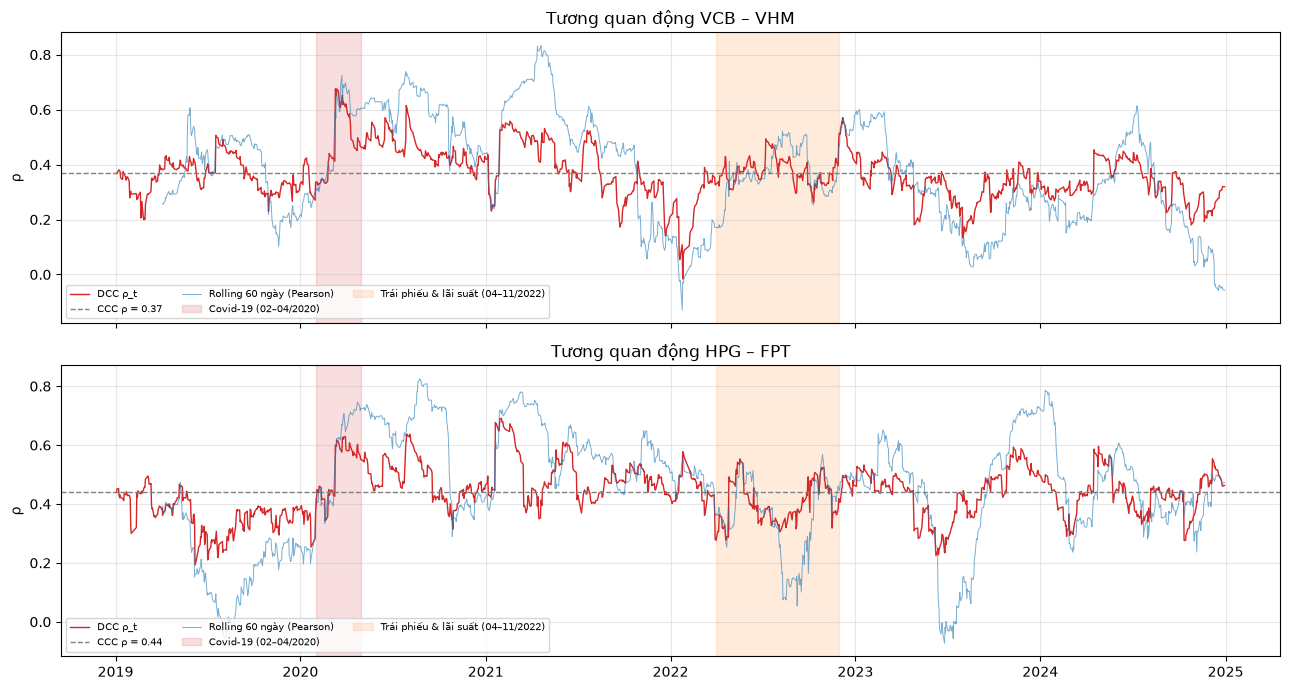

In [5]:
# ===================== 3a. ĐỒ THỊ CÁC CẶP CHÍNH =====================
pairs_plot = [(x, y) for x, y in CORR_PAIRS if x in tickers and y in tickers]
if not pairs_plot:                                     # nếu mã trong outline không có, lấy 2 cặp đầu
    pairs_plot = [(tickers[i], tickers[j]) for i, j in pairs[:2]]
fig, axes = plt.subplots(len(pairs_plot), 1, figsize=(13, 3.5 * len(pairs_plot)), sharex=True, squeeze=False)
for ax, (x, y) in zip(axes[:, 0], pairs_plot):
    i, j = tickers.index(x), tickers.index(y)
    ax.plot(dates, R[:, i, j], color="tab:red", lw=1, label="DCC ρ_t")
    ax.axhline(Rbar[i, j], color="grey", ls="--", lw=1, label=f"CCC ρ = {Rbar[i, j]:.2f}")
    ax.plot(dates, pd.Series(u[:, i]).rolling(60).corr(pd.Series(u[:, j])).values, color="tab:blue",
            lw=0.7, alpha=0.6, label="Rolling 60 ngày (Pearson)")
    shade_stress(ax)
    ax.set_title(f"Tương quan động {x} – {y}")
    ax.set_ylabel("ρ"); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower left", ncol=3)
plt.tight_layout()
plt.savefig(OUT_DIR / "dcc_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

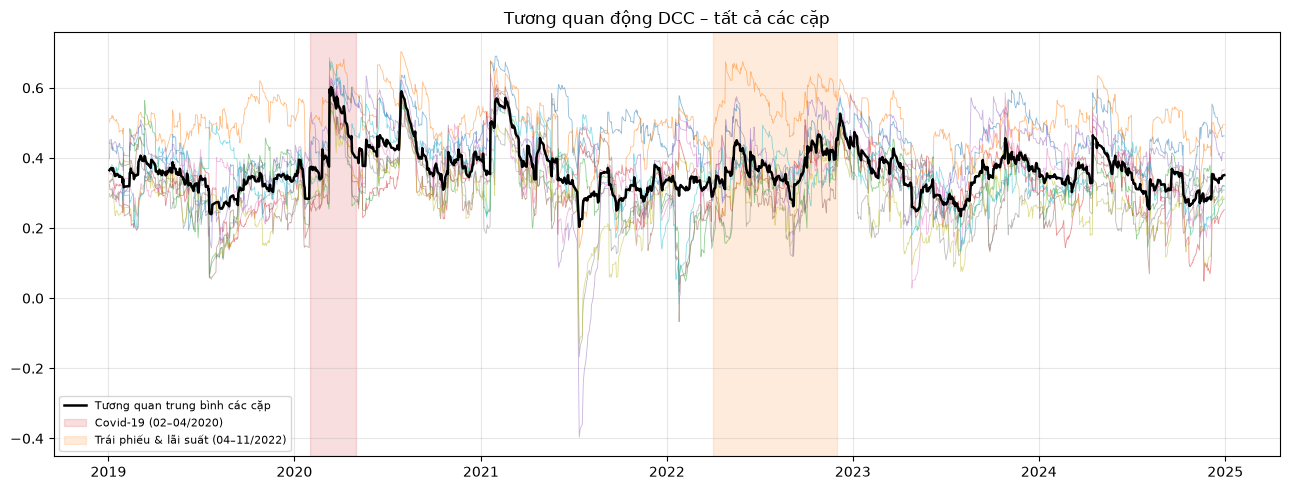

In [6]:
# ===================== 3b. TẤT CẢ CÁC CẶP + TƯƠNG QUAN TRUNG BÌNH =====================
avg_corr = dyn_corr.mean(axis=1)
fig, ax = plt.subplots(figsize=(13, 5))
for c in dyn_corr.columns:
    ax.plot(dates, dyn_corr[c], lw=0.6, alpha=0.5)
ax.plot(dates, avg_corr, color="black", lw=1.8, label="Tương quan trung bình các cặp")
shade_stress(ax)
ax.set_title("Tương quan động DCC – tất cả các cặp"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "dcc_all_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

,Bình thường,Covid-19 (02–04/2020),Trái phiếu & lãi suất (04–11/2022)
FPT-HPG,0.439,0.522,0.403
FPT-MWG,0.487,0.590,0.579
FPT-VCB,0.330,0.388,0.328
FPT-VHM,0.326,0.393,0.351
HPG-MWG,0.391,0.535,0.415
HPG-VCB,0.320,0.403,0.331
HPG-VHM,0.353,0.455,0.373
MWG-VCB,0.294,0.415,0.298
MWG-VHM,0.278,0.405,0.321
VCB-VHM,0.360,0.484,0.376


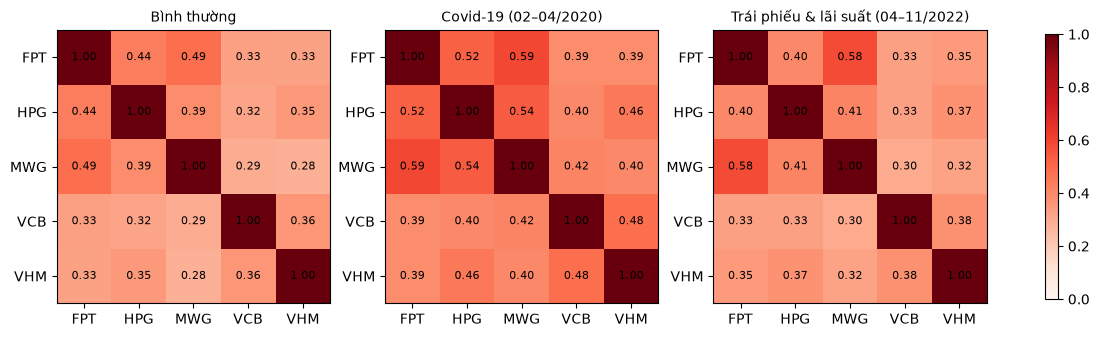

In [7]:
# ===================== 3c. TƯƠNG QUAN THEO GIAI ĐOẠN =====================
def period_mask(idx, a, b):
    return (idx >= pd.Timestamp(a)) & (idx <= pd.Timestamp(b))


stress_any = np.zeros(T, dtype=bool)
period_rows = {}
for name, (a, b) in STRESS_PERIODS.items():
    m = period_mask(dates, a, b)
    stress_any |= m
    period_rows[name] = dyn_corr[m].mean()
period_rows = {"Bình thường": dyn_corr[~stress_any].mean(), **period_rows}
corr_by_period = pd.DataFrame(period_rows)
corr_by_period.loc["TRUNG BÌNH CÁC CẶP"] = corr_by_period.mean()
display(corr_by_period.round(3))
corr_by_period.to_csv(OUT_DIR / "corr_by_period.csv", encoding="utf-8-sig")

# Heatmap tương quan trung bình: bình thường vs từng giai đoạn khủng hoảng
periods = {"Bình thường": ~stress_any, **{n: period_mask(dates, *ab) for n, ab in STRESS_PERIODS.items()}}
fig, axes = plt.subplots(1, len(periods), figsize=(5 * len(periods), 4.3))
for ax, (name, m) in zip(np.atleast_1d(axes), periods.items()):
    Rm = R[m].mean(axis=0)
    im = ax.imshow(Rm, vmin=0, vmax=1, cmap="Reds")
    ax.set_xticks(range(N)); ax.set_xticklabels(tickers); ax.set_yticks(range(N)); ax.set_yticklabels(tickers)
    for i in range(N):
        for j in range(N):
            ax.text(j, i, f"{Rm[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(name, fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(OUT_DIR / "corr_heatmap_by_period.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Diễn giải cốt lõi
- **a** đo tốc độ tương quan phản ứng với cú sốc chung mới: a lớn ⇒ tương quan "nhảy" mạnh sau một phiên cả thị trường cùng giảm.
- **b** đo độ bền: b lớn ⇒ mức tương quan hiện tại phụ thuộc chủ yếu vào quá khứ, thay đổi từ từ.
- **a + b → 1**: cú sốc tương quan tắt rất chậm (xem half-life ở bảng tham số) ⇒ sau khủng hoảng, tương quan cao **duy trì nhiều tháng**, đa dạng hoá kém hiệu quả kéo dài.

### Gợi ý trả lời vấn đáp
**Câu 1 – Vì sao không dùng ma trận tương quan Pearson?** Pearson cho **một con số trung bình cả giai đoạn**, coi tương quan bất biến và chịu nhiễu bởi biến động thay đổi (heteroskedasticity làm tương quan mẫu bị chệch lên khi biến động cao). DCC: (i) lọc biến động riêng bằng GARCH trước, (ii) cho tương quan cập nhật hằng ngày theo cú sốc mới, (iii) cho $H_t$ dự báo được để tính VaR có điều kiện. LR test và AIC/BIC ở mục 2 chứng minh DCC khớp dữ liệu tốt hơn.

**Câu 2 – a + b ≈ 1 thì tương quan có đặc điểm gì?** Tương quan có **trí nhớ dài**: một cú sốc chung (ví dụ Covid) đẩy tương quan lên và mức cao đó tồn tại rất lâu trước khi quay về $\bar Q$; tương quan gần như "đi bộ ngẫu nhiên" quanh mức dài hạn. Hàm ý: không thể kỳ vọng đa dạng hoá phục hồi nhanh sau khủng hoảng.